# Сегментация трещин на DeepCrack

Обучение U-Net и сравнение с классическими методами компьютерного зрения на одинаковой test-выборке.


In [7]:
from __future__ import print_function, division

import copy
import os
import random
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, models, transforms
import torchvision
from tqdm.auto import tqdm

plt.ion()

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("device:", device, "|", device_name)
print("torch:", torch.__version__, "| cuda:", torch.version.cuda)


device: cuda:0 | NVIDIA GeForce RTX 3060 Laptop GPU
torch: 2.6.0+cu124 | cuda: 12.4


c:\python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Локальный запуск

Ноутбук запускается из корня проекта. CUDA ускоряет обучение, но при её отсутствии автоматически используется CPU.


In [2]:
print("cwd:", Path.cwd())
print("DeepCrack:", (Path("data")/"DeepCrack").resolve())


cwd: c:\Users\lazdi\Documents\ITMO\Subjects\neuro_computing\lab3
meta_imagenet: C:\Users\lazdi\Documents\ITMO\Subjects\neuro_computing\lab3\data\meta_imagenet
DeepCrack: C:\Users\lazdi\Documents\ITMO\Subjects\neuro_computing\lab3\data\DeepCrack


Обучение на CPU занимает больше времени. Код автоматически использует CUDA, если она доступна.


# Семантическая сегментация с U-Net

Пайплайн читает пары изображение--маска, выполняет аугментации на лету и обучает U-Net на DeepCrack. Затем результат сравнивается с классическими методами OpenCV.


## Данные DeepCrack и DataLoader

Train-часть делится на обучение и validation с фиксированным seed; исходная test-часть остаётся только для финальной оценки.


In [8]:
DEEPCRACK_ROOT = Path("data/DeepCrack")
paths = {
    "train_img": DEEPCRACK_ROOT / "train_img",
    "train_lab": DEEPCRACK_ROOT / "train_lab",
    "test_img": DEEPCRACK_ROOT / "test_img",
    "test_lab": DEEPCRACK_ROOT / "test_lab",
}
assert all(p.exists() for p in paths.values()), paths
IMG_SIZE = 256

def list_images(folder: Path):
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    return sorted([p for p in folder.iterdir() if p.suffix.lower() in exts])

def pair_by_stem(images, masks):
    mask_map = {p.stem: p for p in masks}
    pairs = [(img, mask_map[img.stem]) for img in images if img.stem in mask_map]
    return pairs if pairs else list(zip(images, masks))

train_pairs = pair_by_stem(list_images(paths["train_img"]), list_images(paths["train_lab"]))
test_pairs = pair_by_stem(list_images(paths["test_img"]), list_images(paths["test_lab"]))
print("train/test pairs:", len(train_pairs), len(test_pairs))

class CrackSegDataset(Dataset):
    def __init__(self, pairs, image_size=IMG_SIZE, augment=False):
        self.pairs = pairs
        self.image_size = image_size
        self.augment = augment
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")
        img = img.resize((self.image_size, self.image_size), Image.BILINEAR)
        mask = mask.resize((self.image_size, self.image_size), Image.NEAREST)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
        mask_bin = (np.asarray(mask, dtype=np.float32) > 127).astype(np.int64)
        if self.augment and random.random() < 0.5:
            img_np = np.ascontiguousarray(img_np[:, ::-1])
            mask_bin = np.ascontiguousarray(mask_bin[:, ::-1])
        return torch.from_numpy(img_np.transpose(2, 0, 1)), torch.from_numpy(mask_bin)

idx_all = list(range(len(train_pairs)))
idx_train, idx_val = train_test_split(idx_all, test_size=0.2, random_state=SEED)
ds_train = CrackSegDataset([train_pairs[i] for i in idx_train], augment=True)
ds_val = CrackSegDataset([train_pairs[i] for i in idx_val], augment=False)
ds_test = CrackSegDataset(test_pairs, augment=False)
loader_train = DataLoader(ds_train, batch_size=8, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
loader_val = DataLoader(ds_val, batch_size=8, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
loader_test = DataLoader(ds_test, batch_size=8, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
print(ds_train[0][0].shape, ds_train[0][1].shape)


train/test pairs: 300 237
torch.Size([3, 256, 256]) torch.Size([256, 256])


## 2.4. Визуализация пар изображение / маска


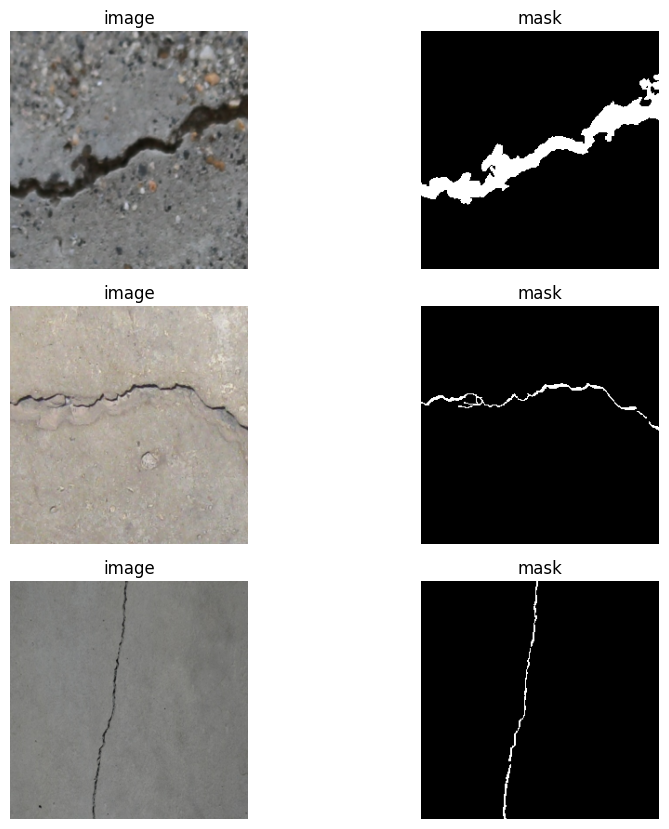

In [9]:
def show_crack_pairs(dataset, n=3):
    plt.figure(figsize=(10, 2.8 * n))
    for i in range(n):
        x, y = dataset[i]
        ax = plt.subplot(n, 2, 2 * i + 1); ax.imshow(x.permute(1, 2, 0)); ax.set_title("image"); ax.axis("off")
        ax = plt.subplot(n, 2, 2 * i + 2); ax.imshow(y.numpy(), cmap="gray"); ax.set_title("mask"); ax.axis("off")
    plt.tight_layout(); plt.show()
show_crack_pairs(ds_val, n=3)


## 2.6. Создание модели U-Net

U-Net — это архитектура сверточной нейронной сети, предназначенная для быстрой и точной сегментации изображений. Он очень хорошо показал себя в нескольких задачах и по сей день является одной из самых популярных архитектур в области семантической сегментации.

<figure>
<img src="https://miro.medium.com/max/1050/1*hzufVrlQYVs_Lj-vHw8SgQ.png" width="1000">
</figure> 


- Кодер захватывает объекты в разных масштабах изображений, используя традиционный стек сверточных слоев и слоев максимального объединения. Конкретно говоря, блок в кодере состоит из многократного использования двух сверточных слоев (k = 3, s = 1), за каждым из которых следует слой нелинейности, и слой максимального объединения (k = 2, s = 2). ). Для каждого блока свертки и связанной с ним операции максимального объединения количество карт объектов удваивается, чтобы сеть могла эффективно изучать сложные структуры.

- Путь декодера представляет собой симметричный расширяющийся аналог, использующий транспонированные свертки. Этот тип сверточного слоя представляет собой метод повышающей дискретизации с обучаемыми параметрами и выполняет обратное (понижающее) объединение слоев, таких как максимальный пул. Подобно кодеру, за каждым блоком свертки следует такой слой свертки вверх. Количество карт признаков в каждом блоке уменьшается вдвое. Поскольку воссоздание маски сегментации из небольшой карты объектов является довольно сложной задачей для сети, выходные данные после каждого сверточного слоя дополняются картами объектов соответствующего блока кодировщика. Карты объектов слоя кодировщика обрезаются, если размеры превышают размеры соответствующих слоев декодера.

- В конце выходные данные проходят еще один слой свертки (k=1, s=1) с количеством карт объектов, равным количеству определенных меток. В результате получается U-образная сверточная сеть, которая предлагает элегантное решение для хорошей локализации и использования контекста.


In [10]:
@torch.jit.script
def autocrop(encoder_layer: torch.Tensor, decoder_layer: torch.Tensor):
    """
    Обрезает encoder_layer по размеру decoder_layer,
     так что слияние (конкатенация) между уровнями/блоками возможно.
     Это необходимо только для входных размеров != 2**n 
     для 'same' padding и всегда требуется для 'valid' padding.
    """
    if encoder_layer.shape[2:] != decoder_layer.shape[2:]:
        ds = encoder_layer.shape[2:]
        es = decoder_layer.shape[2:]
        assert ds[0] >= es[0]
        assert ds[1] >= es[1]
        if encoder_layer.dim() == 4:  # 2D
            encoder_layer = encoder_layer[
                            :,
                            :,
                            ((ds[0] - es[0]) // 2):((ds[0] + es[0]) // 2),
                            ((ds[1] - es[1]) // 2):((ds[1] + es[1]) // 2)
                            ]
        elif encoder_layer.dim() == 5:  # 3D
            assert ds[2] >= es[2]
            encoder_layer = encoder_layer[
                            :,
                            :,
                            ((ds[0] - es[0]) // 2):((ds[0] + es[0]) // 2),
                            ((ds[1] - es[1]) // 2):((ds[1] + es[1]) // 2),
                            ((ds[2] - es[2]) // 2):((ds[2] + es[2]) // 2),
                            ]
    return encoder_layer, decoder_layer


def conv_layer(dim: int):
    if dim == 3:
        return nn.Conv3d
    elif dim == 2:
        return nn.Conv2d


def get_conv_layer(in_channels: int,
                   out_channels: int,
                   kernel_size: int = 3,
                   stride: int = 1,
                   padding: int = 1,
                   bias: bool = True,
                   dim: int = 2):
    return conv_layer(dim)(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding,
                           bias=bias)


def conv_transpose_layer(dim: int):
    if dim == 3:
        return nn.ConvTranspose3d
    elif dim == 2:
        return nn.ConvTranspose2d


def get_up_layer(in_channels: int,
                 out_channels: int,
                 kernel_size: int = 2,
                 stride: int = 2,
                 dim: int = 3,
                 up_mode: str = 'transposed',
                 ):
    if up_mode == 'transposed':
        return conv_transpose_layer(dim)(in_channels, out_channels, kernel_size=kernel_size, stride=stride)
    else:
        return nn.Upsample(scale_factor=2.0, mode=up_mode)


def maxpool_layer(dim: int):
    if dim == 3:
        return nn.MaxPool3d
    elif dim == 2:
        return nn.MaxPool2d


def get_maxpool_layer(kernel_size: int = 2,
                      stride: int = 2,
                      padding: int = 0,
                      dim: int = 2):
    return maxpool_layer(dim=dim)(kernel_size=kernel_size, stride=stride, padding=padding)


def get_activation(activation: str):
    if activation == 'relu':
        return nn.ReLU()
    elif activation == 'leaky':
        return nn.LeakyReLU(negative_slope=0.1)
    elif activation == 'elu':
        return nn.ELU()


def get_normalization(normalization: str,
                      num_channels: int,
                      dim: int):
    if normalization == 'batch':
        if dim == 3:
            return nn.BatchNorm3d(num_channels)
        elif dim == 2:
            return nn.BatchNorm2d(num_channels)
    elif normalization == 'instance':
        if dim == 3:
            return nn.InstanceNorm3d(num_channels)
        elif dim == 2:
            return nn.InstanceNorm2d(num_channels)
    elif 'group' in normalization:
        num_groups = int(normalization.partition('group')[-1])  # get the group size from string
        return nn.GroupNorm(num_groups=num_groups, num_channels=num_channels)

In [11]:
class Concatenate(nn.Module):
    def __init__(self):
        super(Concatenate, self).__init__()

    def forward(self, layer_1, layer_2):
        x = torch.cat((layer_1, layer_2), 1)

        return x


class DownBlock(nn.Module):
    """
    Вспомогательный модуль, который выполняет 2 свертки и 1 MaxPool.
     После каждой свертки следует активация.
     После каждой свертки следует слой нормализации.
    """

    def __init__(self,
                 in_channels: int,
                 out_channels: int,
                 pooling: bool = True,
                 activation: str = 'relu',
                 normalization: str = None,
                 dim: str = 2,
                 conv_mode: str = 'same'):
        super().__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.pooling = pooling
        self.normalization = normalization
        if conv_mode == 'same':
            self.padding = 1
        elif conv_mode == 'valid':
            self.padding = 0
        self.dim = dim
        self.activation = activation

        # conv layers
        self.conv1 = get_conv_layer(self.in_channels, self.out_channels, kernel_size=3, stride=1, padding=self.padding,
                                    bias=True, dim=self.dim)
        self.conv2 = get_conv_layer(self.out_channels, self.out_channels, kernel_size=3, stride=1, padding=self.padding,
                                    bias=True, dim=self.dim)

        # pooling layer
        if self.pooling:
            self.pool = get_maxpool_layer(kernel_size=2, stride=2, padding=0, dim=self.dim)

        # activation layers
        self.act1 = get_activation(self.activation)
        self.act2 = get_activation(self.activation)

        # normalization layers
        if self.normalization:
            self.norm1 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)
            self.norm2 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)

    def forward(self, x):
        y = self.conv1(x)  # convolution 1
        y = self.act1(y)  # activation 1
        if self.normalization:
            y = self.norm1(y)  # normalization 1
        y = self.conv2(y)  # convolution 2
        y = self.act2(y)  # activation 2
        if self.normalization:
            y = self.norm2(y)  # normalization 2

        before_pooling = y  # save the outputs before the pooling operation
        if self.pooling:
            y = self.pool(y)  # pooling
        return y, before_pooling


class UpBlock(nn.Module):
    """
      Вспомогательный модуль, который выполняет 2 свертки и 1 UpConvolution/Upsample.
     После каждой свертки следует активация.
     После каждой свертки следует слой нормализации.
    """

    def __init__(self,
                 in_channels: int,
                 out_channels: int,
                 activation: str = 'relu',
                 normalization: str = None,
                 dim: int = 3,
                 conv_mode: str = 'same',
                 up_mode: str = 'transposed'
                 ):
        super().__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.normalization = normalization
        if conv_mode == 'same':
            self.padding = 1
        elif conv_mode == 'valid':
            self.padding = 0
        self.dim = dim
        self.activation = activation
        self.up_mode = up_mode

        # upconvolution/upsample layer
        self.up = get_up_layer(self.in_channels, self.out_channels, kernel_size=2, stride=2, dim=self.dim,
                               up_mode=self.up_mode)

        # conv layers
        self.conv0 = get_conv_layer(self.in_channels, self.out_channels, kernel_size=1, stride=1, padding=0,
                                    bias=True, dim=self.dim)
        self.conv1 = get_conv_layer(2 * self.out_channels, self.out_channels, kernel_size=3, stride=1,
                                    padding=self.padding,
                                    bias=True, dim=self.dim)
        self.conv2 = get_conv_layer(self.out_channels, self.out_channels, kernel_size=3, stride=1, padding=self.padding,
                                    bias=True, dim=self.dim)

        # activation layers
        self.act0 = get_activation(self.activation)
        self.act1 = get_activation(self.activation)
        self.act2 = get_activation(self.activation)

        # normalization layers
        if self.normalization:
            self.norm0 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)
            self.norm1 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)
            self.norm2 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)

        # concatenate layer
        self.concat = Concatenate()

    def forward(self, encoder_layer, decoder_layer):
        """ Forward pass
         Аргументы:
             encoder_layer: тензор из пути кencoder pathway
             decoder_layer: тензор из decoder pathway (будет обновлен)
        """
        up_layer = self.up(decoder_layer)  # up-convolution/up-sampling
        cropped_encoder_layer, dec_layer = autocrop(encoder_layer, up_layer)  # cropping

        if self.up_mode != 'transposed':
            # We need to reduce the channel dimension with a conv layer
            up_layer = self.conv0(up_layer)  # convolution 0
        up_layer = self.act0(up_layer)  # activation 0
        if self.normalization:
            up_layer = self.norm0(up_layer)  # normalization 0

        merged_layer = self.concat(up_layer, cropped_encoder_layer)  # concatenation
        y = self.conv1(merged_layer)  # convolution 1
        y = self.act1(y)  # activation 1
        if self.normalization:
            y = self.norm1(y)  # normalization 1
        y = self.conv2(y)  # convolution 2
        y = self.act2(y)  # acivation 2
        if self.normalization:
            y = self.norm2(y)  # normalization 2
        return y

In [12]:
class UNet(nn.Module):
    def __init__(self,
                 in_channels: int = 1,
                 out_channels: int = 2,
                 n_blocks: int = 4,
                 start_filters: int = 32,
                 activation: str = 'relu',
                 normalization: str = 'batch',
                 conv_mode: str = 'same',
                 dim: int = 2,
                 up_mode: str = 'transposed'
                 ):
        super().__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.n_blocks = n_blocks
        self.start_filters = start_filters
        self.activation = activation
        self.normalization = normalization
        self.conv_mode = conv_mode
        self.dim = dim
        self.up_mode = up_mode

        self.down_blocks = []
        self.up_blocks = []

        # create encoder path
        for i in range(self.n_blocks):
            num_filters_in = self.in_channels if i == 0 else num_filters_out
            num_filters_out = self.start_filters * (2 ** i)
            pooling = True if i < self.n_blocks - 1 else False

            down_block = DownBlock(in_channels=num_filters_in,
                                   out_channels=num_filters_out,
                                   pooling=pooling,
                                   activation=self.activation,
                                   normalization=self.normalization,
                                   conv_mode=self.conv_mode,
                                   dim=self.dim)

            self.down_blocks.append(down_block)

        # create decoder path (requires only n_blocks-1 blocks)
        for i in range(n_blocks - 1):
            num_filters_in = num_filters_out
            num_filters_out = num_filters_in // 2

            up_block = UpBlock(in_channels=num_filters_in,
                               out_channels=num_filters_out,
                               activation=self.activation,
                               normalization=self.normalization,
                               conv_mode=self.conv_mode,
                               dim=self.dim,
                               up_mode=self.up_mode)

            self.up_blocks.append(up_block)

        # final convolution
        self.conv_final = get_conv_layer(num_filters_out, self.out_channels, kernel_size=1, stride=1, padding=0,
                                         bias=True, dim=self.dim)

        # add the list of modules to current module
        self.down_blocks = nn.ModuleList(self.down_blocks)
        self.up_blocks = nn.ModuleList(self.up_blocks)

        # initialize the weights
        self.initialize_parameters()

    @staticmethod
    def weight_init(module, method, **kwargs):
        if isinstance(module, (nn.Conv3d, nn.Conv2d, nn.ConvTranspose3d, nn.ConvTranspose2d)):
            method(module.weight, **kwargs)  # weights

    @staticmethod
    def bias_init(module, method, **kwargs):
        if isinstance(module, (nn.Conv3d, nn.Conv2d, nn.ConvTranspose3d, nn.ConvTranspose2d)):
            method(module.bias, **kwargs)  # bias

    def initialize_parameters(self,
                              method_weights=nn.init.xavier_uniform_,
                              method_bias=nn.init.zeros_,
                              kwargs_weights={},
                              kwargs_bias={}
                              ):
        for module in self.modules():
            self.weight_init(module, method_weights, **kwargs_weights)  # initialize weights
            self.bias_init(module, method_bias, **kwargs_bias)  # initialize bias

    def forward(self, x: torch.tensor):
        encoder_output = []

        # Encoder pathway
        for module in self.down_blocks:
            x, before_pooling = module(x)
            encoder_output.append(before_pooling)

        # Decoder pathway
        for i, module in enumerate(self.up_blocks):
            before_pool = encoder_output[-(i + 2)]
            x = module(before_pool, x)

        x = self.conv_final(x)

        return x

    def __repr__(self):
        attributes = {attr_key: self.__dict__[attr_key] for attr_key in self.__dict__.keys() if '_' not in attr_key[0] and 'training' not in attr_key}
        d = {self.__class__.__name__: attributes}
        return f'{d}'

__Downsample block__
<figure>
<img src="https://miro.medium.com/max/1050/1*SsTwShoqsGjVCl4Ms7qpcw.png" width="1000">
</figure> 

__Upsample block__
<figure>
<img src="https://miro.medium.com/max/1050/1*ni1_F1MOwKnnHVEeQ43BRQ.png" width="1000">
</figure> 


Для нашего класса Unet нам просто нужно объединить эти блоки и убедиться, что правильные слои от кодировщика соединены с декодером (пропустить пути). Эти слои необходимо обрезать, если их размеры не совпадают с соответствующими слоями из декодера. В таких случаях используется функция автообрезки. Для слияния выполняется конкатенацию по измерению канала. Вместо транспонированных сверток мы могли бы также использовать слои повышающей дискретизации (методы интерполяции), за которыми следует блок свертки 1x1 или 3x3, чтобы уменьшить размер канала. Для трехмерного ввода рассмотрите возможность использования трилинейной интерполяции.

## 2.7. Инициализация модели

In [13]:
# Как в примере С10; для DeepCrack — RGB (3 канала), 2 класса (фон / трещина)
model = UNet(in_channels=3,
             out_channels=2,
             n_blocks=4,
             start_filters=32,
             activation='relu',
             normalization='batch',
             conv_mode='same',
             dim=2)

x = torch.randn(size=(1, 3, IMG_SIZE, IMG_SIZE), dtype=torch.float32)
with torch.no_grad():
    out = model(x)
print(f'Out: {out.shape}')

unet = model.to(device)
print(sum(p.numel() for p in unet.parameters()) / 1e6, 'M params')


Out: torch.Size([1, 2, 256, 256])
1.97213 M params


__!!! Input sizes !!!__  
Для обеспечения правильной семантической конкатенации рекомендуется использовать входные размеры, которые возвращают четные пространственные измерения в каждом блоке кодировщика, кроме последнего. Например: Размер ввода 120² дает промежуточные выходные формы [60², 30², 15²] в пути кодера для U-Net с depth=4 . U-Net с глубиной = 5 с тем же размером входа не рекомендуется, так как следует избегать операции максимального объединения на нечетных пространственных измерениях (например, на входе 15²).

## 2.8. Создадим класс обучения
Учтем следующие параметры:
- модель: напр. U-Net
- устройство: CPU или GPU
- критерий: функция потерь (например, CrossEntropyLoss, DiceCoefficientLoss)
- оптимизатор: например. SGD
- training_DataLoader: a training dataloader
- validation_DataLoader: a validation dataloader
- lr_scheduler: планировщик скорости обучения (необязательно)
- epochs: количество эпох, которые мы хотим тренировать
- эпоха: номер эпохи, с которой должно начаться обучение

## 2.9–2.10. Обучение U-Net на DeepCrack

Обучаем модель из раздела 2.6–2.7 на `data/DeepCrack` (CrossEntropyLoss, Dice/IoU).


In [14]:
def dice_iou_from_logits(logits, target, crack_class=1, eps=1e-6):
    preds = logits.argmax(1)
    pred_c = (preds == crack_class).float(); true_c = (target == crack_class).float()
    inter = (pred_c * true_c).sum((1, 2))
    dice = ((2 * inter + eps) / (pred_c.sum((1, 2)) + true_c.sum((1, 2)) + eps)).mean().item()
    iou = ((inter + eps) / (pred_c.sum((1, 2)) + true_c.sum((1, 2)) - inter + eps)).mean().item()
    return dice, iou

def train_unet(model, loader_train, loader_val, epochs=25, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 3.0], device=device))
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    history = defaultdict(list)
    best_state, best_dice = copy.deepcopy(model.state_dict()), -1.0
    for epoch in range(1, epochs + 1):
        model.train(); tr_loss = tr_dice = n = 0.0
        for x, y in tqdm(loader_train, leave=False, desc=f"train {epoch}"):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x); loss = criterion(logits, y)
            loss.backward(); optimizer.step()
            d, _ = dice_iou_from_logits(logits.detach(), y)
            bs = x.size(0); tr_loss += loss.item() * bs; tr_dice += d * bs; n += bs
        model.eval(); va_loss = va_dice = va_iou = m = 0.0
        with torch.no_grad():
            for x, y in loader_val:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                logits = model(x); loss = criterion(logits, y)
                d, iou = dice_iou_from_logits(logits, y)
                bs = x.size(0); va_loss += loss.item() * bs; va_dice += d * bs; va_iou += iou * bs; m += bs
        tr_loss, tr_dice, va_loss, va_dice, va_iou = tr_loss/n, tr_dice/n, va_loss/m, va_dice/m, va_iou/m
        scheduler.step(va_dice)
        for k, v in [("train_loss", tr_loss), ("val_loss", va_loss), ("train_dice", tr_dice), ("val_dice", va_dice), ("val_iou", va_iou)]:
            history[k].append(v)
        print(f"epoch {epoch:02d} | train {tr_loss:.4f}/{tr_dice:.4f} | val {va_loss:.4f}/{va_dice:.4f}/{va_iou:.4f}")
        if va_dice > best_dice:
            best_dice = va_dice; best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state); print("best val dice:", best_dice)
    return model, history

unet, hist_unet = train_unet(unet, loader_train, loader_val, epochs=25, lr=1e-3)
Path("artifacts").mkdir(exist_ok=True)
torch.save(unet.state_dict(), "artifacts/unet_deepcrack.pt")


train 1:   0%|          | 0/30 [00:00<?, ?it/s]

epoch 01 | train 0.6012/0.2895 | val 0.4015/0.1791/0.1099


epoch 02 | train 0.3821/0.5929 | val 0.2539/0.5079/0.3951


epoch 03 | train 0.2746/0.6399 | val 0.2953/0.5704/0.4481


epoch 04 | train 0.2343/0.6409 | val 0.2176/0.5627/0.4473


epoch 05 | train 0.1774/0.6402 | val 0.1500/0.5657/0.4531


... (16 outputs left out)

epoch 22 | train 0.0497/0.7681 | val 0.0423/0.7459/0.6264


epoch 23 | train 0.0520/0.7581 | val 0.0454/0.7121/0.5965


epoch 24 | train 0.0581/0.7590 | val 0.0600/0.6606/0.5559


epoch 25 | train 0.0542/0.7511 | val 0.0457/0.7194/0.5994
best val dice: 0.7458701610565186


## 2.11. Визуализация обучения


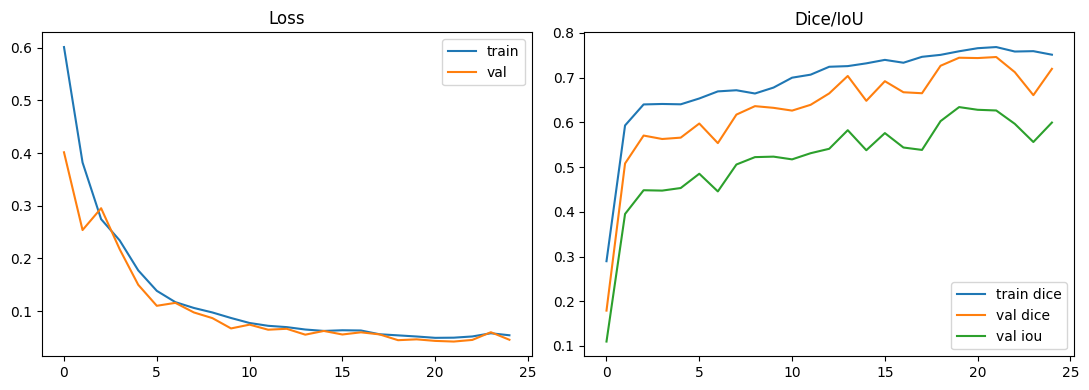

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_unet["train_loss"], label="train"); ax[0].plot(hist_unet["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist_unet["train_dice"], label="train dice"); ax[1].plot(hist_unet["val_dice"], label="val dice"); ax[1].plot(hist_unet["val_iou"], label="val iou"); ax[1].set_title("Dice/IoU"); ax[1].legend()
plt.tight_layout(); plt.show()


## 2.12. Применение модели


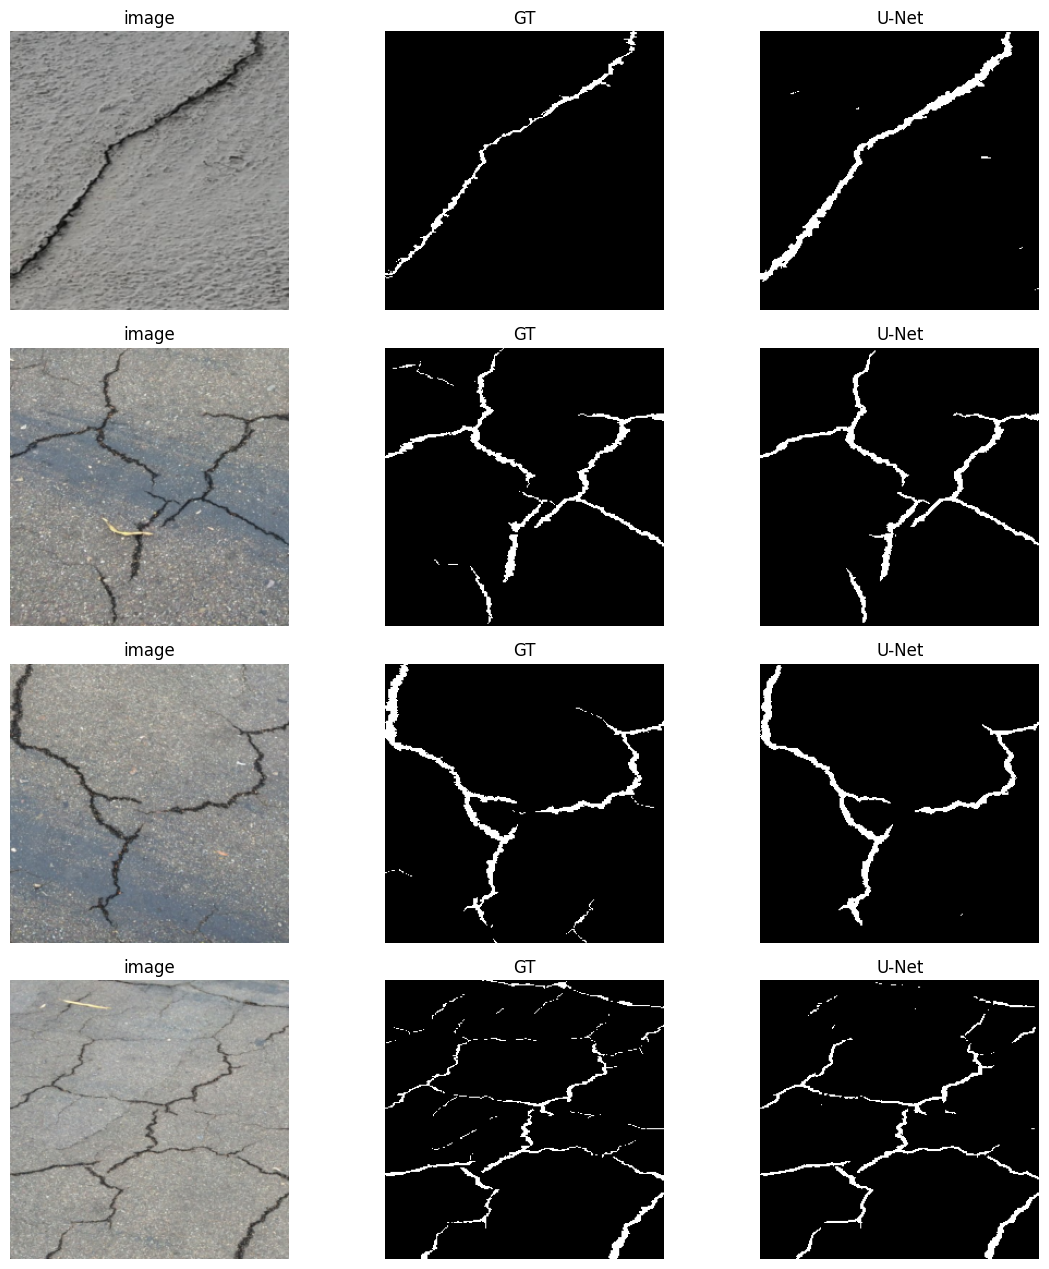

U-Net test Dice=0.7987, IoU=0.6873


In [16]:
@torch.no_grad()
def visualize_unet(model, dataset, n=4):
    model.eval(); plt.figure(figsize=(12, 3.2 * n))
    for i in range(n):
        x, y = dataset[i]
        pred = model(x.unsqueeze(0).to(device, non_blocking=True)).argmax(1)[0].cpu().numpy()
        img = x.permute(1, 2, 0).numpy()
        for j, (title, arr, cmap) in enumerate([("image", img, None), ("GT", y.numpy(), "gray"), ("U-Net", pred, "gray")]):
            ax = plt.subplot(n, 3, 3 * i + j + 1)
            ax.imshow(arr, cmap=cmap) if cmap else ax.imshow(arr)
            ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

@torch.no_grad()
def eval_loader_metrics(model, loader):
    model.eval(); dices, ious = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        d, iou = dice_iou_from_logits(model(x), y); dices.append(d); ious.append(iou)
    return float(np.mean(dices)), float(np.mean(ious))

visualize_unet(unet, ds_test, n=4)
test_dice, test_iou = eval_loader_metrics(unet, loader_test)
print(f"U-Net test Dice={test_dice:.4f}, IoU={test_iou:.4f}")


## 2.13. Классическая сегментация без нейросети и сравнение

Сравниваем adaptive threshold + Canny + морфологию с U-Net.

Сравниваем **три** пайплайна на одних и тех же картинках, затем перебором параметров ищем лучший Dice на `val` и проверяем на `test`.


### A / B / C — три варианта предобработки

- **A. baseline** — только GaussianBlur → adaptive + Canny → морфология  
- **B. denoise** — bilateral + median (уменьшаем зерно, края сохраняем)  
- **C. fourier** — denoise + low-pass в спектре Фурье → обратное FFT, затем то же детектирование


In [17]:
import cv2

def fourier_lowpass(gray_uint8, keep_ratio=0.15):
    f = np.fft.fft2(gray_uint8.astype(np.float32))
    fshift = np.fft.fftshift(f)
    h, w = gray_uint8.shape
    cy, cx = h // 2, w // 2
    radius = max(1, int(min(h, w) * keep_ratio))
    y, x = np.ogrid[:h, :w]
    mask = ((y - cy) ** 2 + (x - cx) ** 2) <= radius ** 2
    fshift_filt = np.where(mask, fshift, 0)
    img_back = np.fft.ifft2(np.fft.ifftshift(fshift_filt)).real
    return cv2.normalize(img_back, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def remove_small_components(binary_uint8, min_area=40):
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary_uint8, connectivity=8)
    out = np.zeros_like(binary_uint8)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            out[labels == i] = 255
    return out

def _detect(gray, block_size=31, C=4, canny1=40, canny2=120, min_area=40):
    if block_size % 2 == 0:
        block_size += 1
    thr = cv2.adaptiveThreshold(
        gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, block_size, C
    )
    edges = cv2.Canny(gray, canny1, canny2)
    fused = cv2.bitwise_or(thr, edges)
    k3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    k5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    fused = cv2.morphologyEx(fused, cv2.MORPH_OPEN, k3, iterations=2)
    fused = cv2.morphologyEx(fused, cv2.MORPH_CLOSE, k5, iterations=2)
    fused = remove_small_components(fused, min_area=min_area)
    return (fused > 0).astype(np.uint8)

def classical_A(img_rgb_uint8, **kw):
    gray = cv2.cvtColor(img_rgb_uint8, cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)
    return _detect(gray, **kw)

def classical_B(img_rgb_uint8, **kw):
    gray = cv2.cvtColor(img_rgb_uint8, cv2.COLOR_RGB2GRAY)
    gray = cv2.bilateralFilter(gray, d=7, sigmaColor=50, sigmaSpace=50)
    gray = cv2.medianBlur(gray, 5)
    return _detect(gray, **kw)

def classical_C(img_rgb_uint8, keep_ratio=0.15, **kw):
    gray = cv2.cvtColor(img_rgb_uint8, cv2.COLOR_RGB2GRAY)
    gray = cv2.bilateralFilter(gray, d=7, sigmaColor=50, sigmaSpace=50)
    gray = cv2.medianBlur(gray, 5)
    gray = fourier_lowpass(gray, keep_ratio=keep_ratio)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    return _detect(gray, **kw)

METHODS = {
    "A baseline": classical_A,
    "B denoise": classical_B,
    "C fourier": classical_C,
}

def dice_iou_numpy(pred, gt, eps=1e-6):
    pred = pred.astype(np.float32); gt = gt.astype(np.float32)
    inter = (pred * gt).sum()
    dice = float((2 * inter + eps) / (pred.sum() + gt.sum() + eps))
    iou = float((inter + eps) / (pred.sum() + gt.sum() - inter + eps))
    return dice, iou

def eval_method(fn, dataset, **kw):
    dices, ious = [], []
    for i in range(len(dataset)):
        x, y = dataset[i]
        img = (x.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
        d, iou = dice_iou_numpy(fn(img, **kw), y.numpy().astype(np.uint8))
        dices.append(d); ious.append(iou)
    return float(np.mean(dices)), float(np.mean(ious))


### Визуальное сравнение A / B / C на одних примерах


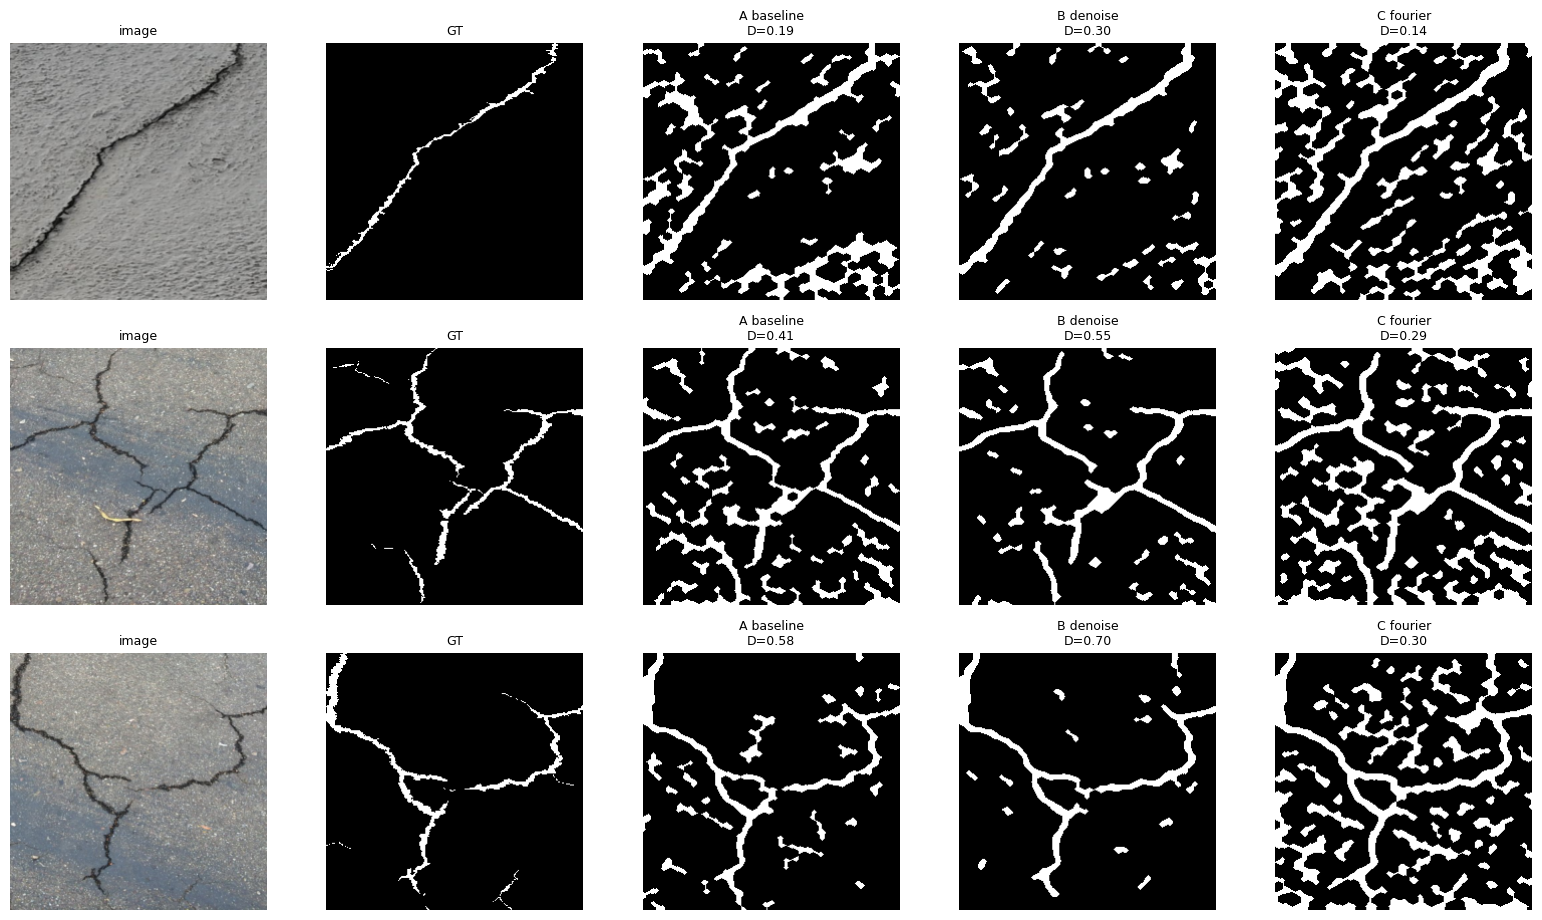

Средние метрики на test (дефолтные параметры):
  A baseline    Dice=0.3051  IoU=0.2071
  B denoise     Dice=0.3612  IoU=0.2484
  C fourier     Dice=0.2868  IoU=0.1914


In [18]:
n_show = min(3, len(ds_test))
fig, axes = plt.subplots(n_show, 5, figsize=(16, 3.1 * n_show))
if n_show == 1:
    axes = np.expand_dims(axes, 0)

for i in range(n_show):
    x, y = ds_test[i]
    img = (x.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    gt = y.numpy().astype(np.uint8)
    preds = {name: fn(img) for name, fn in METHODS.items()}
    panels = [("image", img, None), ("GT", gt, "gray")]
    panels += [(f"{name}\nD={dice_iou_numpy(p, gt)[0]:.2f}", p, "gray") for name, p in preds.items()]
    for j, (title, arr, cmap) in enumerate(panels):
        ax = axes[i, j]
        if cmap:
            ax.imshow(arr, cmap=cmap, vmin=0, vmax=1)
        else:
            ax.imshow(arr)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Средние метрики на test (дефолтные параметры):")
for name, fn in METHODS.items():
    d, iou = eval_method(fn, ds_test)
    print(f"  {name:12s}  Dice={d:.4f}  IoU={iou:.4f}")


### Перебор параметров: ищем лучший Dice на `val`

Подбираем параметры отдельно для **B (denoise)** и **C (fourier)**:
- B: `block_size`, `C`, `min_area`, пороги Canny  
- C: то же + `keep_ratio` (доля низких частот после FFT)

Лучшие параметры каждого метода потом считаем на `test` и сравниваем с U-Net.


In [19]:
from itertools import product

grid_common = {
    "block_size": [21, 31, 41],
    "C": [2, 4, 6],
    "min_area": [20, 60, 120],
    "canny1": [30, 50],
    "canny2": [100, 140],
}
grid_C = {**grid_common, "keep_ratio": [0.08, 0.12, 0.18, 0.25]}

n_search = min(24, len(ds_val))
ds_search = torch.utils.data.Subset(ds_val, list(range(n_search)))

def run_grid(fn, grid, label):
    keys = list(grid.keys())
    combos = list(product(*[grid[k] for k in keys]))
    print(f"[{label}] перебор: {len(combos)} комбинаций на {n_search} val-картинках")
    best = {"dice": -1.0, "params": None, "iou": None}
    rows = []
    for values in tqdm(combos, desc=f"grid {label}"):
        params = dict(zip(keys, values))
        if params["canny2"] <= params["canny1"]:
            continue
        d, iou = eval_method(fn, ds_search, **params)
        rows.append((d, iou, params))
        if d > best["dice"]:
            best = {"dice": d, "iou": iou, "params": params}
    rows.sort(key=lambda t: t[0], reverse=True)
    print(f"\n[{label}] Топ-5 по val Dice:")
    for d, iou, p in rows[:5]:
        print(f"  Dice={d:.4f} IoU={iou:.4f}  {p}")
    return best, rows

best_B, rows_B = run_grid(classical_B, grid_common, "B denoise")
best_C, rows_C = run_grid(classical_C, grid_C, "C fourier")

best_params_B = best_B["params"]
best_params_C = best_C["params"]

val_B, val_Bi = eval_method(classical_B, ds_val, **best_params_B)
test_B, test_Bi = eval_method(classical_B, ds_test, **best_params_B)
val_C, val_Ci = eval_method(classical_C, ds_val, **best_params_C)
test_C, test_Ci = eval_method(classical_C, ds_test, **best_params_C)

print("\n=== Лучшие параметры ===")
print("B:", best_params_B)
print("C:", best_params_C)
print(f"B denoise  val Dice={val_B:.4f}/{val_Bi:.4f} | test Dice={test_B:.4f}/{test_Bi:.4f}")
print(f"C fourier  val Dice={val_C:.4f}/{val_Ci:.4f} | test Dice={test_C:.4f}/{test_Ci:.4f}")
print(f"U-Net      test Dice={test_dice:.4f}, IoU={test_iou:.4f}")


[B denoise] перебор: 108 комбинаций на 24 val-картинках


grid B denoise: 100%|██████████| 108/108 [00:20<00:00,  5.25it/s]



[B denoise] Топ-5 по val Dice:
  Dice=0.4890 IoU=0.3707  {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 50, 'canny2': 100}
  Dice=0.4856 IoU=0.3666  {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 30, 'canny2': 100}
  Dice=0.4789 IoU=0.3673  {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 50, 'canny2': 140}
  Dice=0.4775 IoU=0.3653  {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 30, 'canny2': 140}
  Dice=0.4711 IoU=0.3488  {'block_size': 21, 'C': 6, 'min_area': 60, 'canny1': 50, 'canny2': 100}
[C fourier] перебор: 432 комбинаций на 24 val-картинках


grid C fourier: 100%|██████████| 432/432 [01:58<00:00,  3.64it/s]



[C fourier] Топ-5 по val Dice:
  Dice=0.4498 IoU=0.3333  {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 50, 'canny2': 140, 'keep_ratio': 0.18}
  Dice=0.4491 IoU=0.3332  {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 50, 'canny2': 140, 'keep_ratio': 0.25}
  Dice=0.4481 IoU=0.3313  {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 30, 'canny2': 140, 'keep_ratio': 0.18}
  Dice=0.4470 IoU=0.3313  {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 30, 'canny2': 140, 'keep_ratio': 0.25}
  Dice=0.4365 IoU=0.3216  {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 50, 'canny2': 100, 'keep_ratio': 0.25}

=== Лучшие параметры ===
B: {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 50, 'canny2': 100}
C: {'block_size': 21, 'C': 6, 'min_area': 120, 'canny1': 50, 'canny2': 140, 'keep_ratio': 0.18}
B denoise  val Dice=0.4689/0.3518 | test Dice=0.6065/0.4769
C fourier  val Dice=0.4204/0.3056 | test Dice=0.5785/0.4459
U-Net      test Dice=0.7987, IoU=0.6873


### Визуализация лучшей классики vs GT (и кратко vs U-Net)

Отдельно лучший **B** и лучший **C** (параметры с `val`) рядом с GT и U-Net.


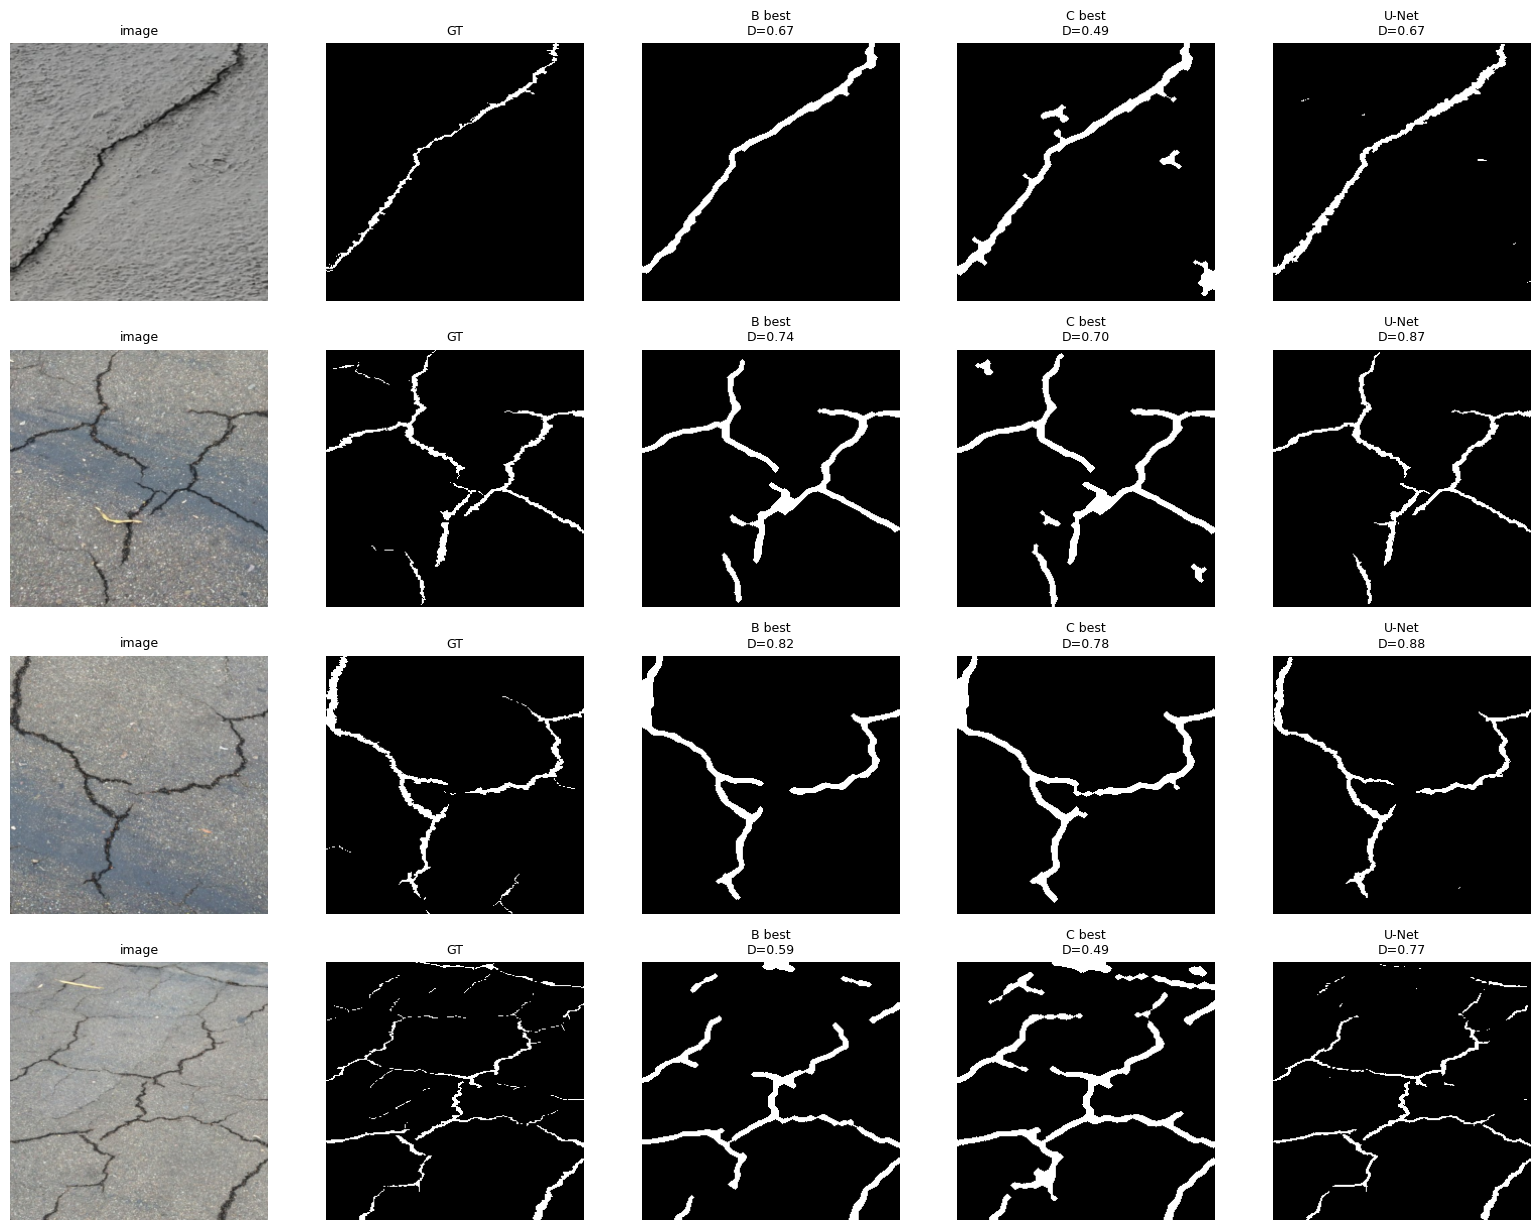

B denoise (best on val) → test Dice=0.6065, IoU=0.4769
C fourier (best on val) → test Dice=0.5785, IoU=0.4459
U-Net                   → test Dice=0.7987, IoU=0.6873


In [20]:
n_show = min(4, len(ds_test))
fig, axes = plt.subplots(n_show, 5, figsize=(16, 3.1 * n_show))
if n_show == 1:
    axes = np.expand_dims(axes, 0)

unet.eval()
for i in range(n_show):
    x, y = ds_test[i]
    img = (x.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    gt = y.numpy().astype(np.uint8)
    pred_b = classical_B(img, **best_params_B)
    pred_c = classical_C(img, **best_params_C)
    with torch.no_grad():
        pred_u = unet(x.unsqueeze(0).to(device)).argmax(1)[0].cpu().numpy().astype(np.uint8)
    db, _ = dice_iou_numpy(pred_b, gt)
    dc, _ = dice_iou_numpy(pred_c, gt)
    du, _ = dice_iou_numpy(pred_u, gt)
    panels = [
        ("image", img, None),
        ("GT", gt, "gray"),
        (f"B best\nD={db:.2f}", pred_b, "gray"),
        (f"C best\nD={dc:.2f}", pred_c, "gray"),
        (f"U-Net\nD={du:.2f}", pred_u, "gray"),
    ]
    for j, (title, arr, cmap) in enumerate(panels):
        ax = axes[i, j]
        if cmap:
            ax.imshow(arr, cmap=cmap, vmin=0, vmax=1)
        else:
            ax.imshow(arr)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

print(f"B denoise (best on val) → test Dice={test_B:.4f}, IoU={test_Bi:.4f}")
print(f"C fourier (best on val) → test Dice={test_C:.4f}, IoU={test_Ci:.4f}")
print(f"U-Net                   → test Dice={test_dice:.4f}, IoU={test_iou:.4f}")


# 5. Использованные материалы:
- https://pytorch.org/tutorials/beginner/finetuning_torchvision_models_tutorial.html
- https://towardsdatascience.com/creating-and-training-a-u-net-model-with-pytorch-for-2d-3d-semantic-segmentation-dataset-fb1f7f80fe55
- https://pytorch.org/tutorials/intermediate/torchvision_tutorial.html

## Итог

U-Net получила на test **Dice 0.7987** и **IoU 0.6873**. Лучший классический пайплайн после настройки на validation получил Dice 0.6065 и IoU 0.4769.
